# GDAL Translate Trial
Testing loading and setting of bbox using gdal translate or warp functionality.

In [32]:
from osgeo import gdal, gdal_array
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import time
from pyproj import CRS, Transformer
from PIL import Image, ImageEnhance
from sklearn.preprocessing import MinMaxScaler

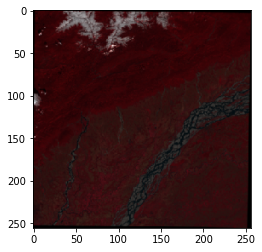

In [37]:
def get_translate(projWin):
    #gdal.GetDriverByName('GTiff').Delete('/vsimem/in_memory_output.tif') [462405.0, 1734315.0, 469905.0, 1741815.0]
    # dataset = gdal.Open('/vsicurl/http://landsat-pds.s3.amazonaws.com/c1/L8/042/034/LC08_L1TP_042034_20170616_20170629_01_T1/LC08_L1TP_042034_20170616_20170629_01_T1_B4.TIF')
    transformer = Transformer.from_crs("EPSG:3857", "EPSG:4326")
    projWin[1], projWin[0] = transformer.transform(projWin[0], projWin[1])
    projWin[3], projWin[2] = transformer.transform(projWin[2], projWin[3])
    dataset = gdal.Open(
        '/vsicurl/http://mobileapp.nesdr.gov.in/out2019.tif',
        gdal.GA_ReadOnly
        )
    dataset = gdal.Warp('', dataset, width=256, height=256,  format='MEM')#outputBounds=projWin,
    im = np.dstack([dataset.GetRasterBand(8).ReadAsArray(),dataset.GetRasterBand(4).ReadAsArray(),dataset.GetRasterBand(3).ReadAsArray()])
    #im = im.astype(np.uint8) * 255
    '''alpha = np.mean(im, axis=2)!=0
    im = np.dstack([im,alpha.astype(np.uint8)*255])'''
    '''img = Image.fromarray(im, mode='RGBA')
    return img'''
    #print(dataset.GetRasterBand(5).GetColorTable())
    s = im.shape
    #im = np.reshape(im,(-1,1))
    '''sc = MinMaxScaler()
    im = sc.fit_transform(im)'''
    im = (im-im.min())/(im.max()-im.min())
    #im = np.reshape(im, s)
    plt.imshow(im)
    plt.show() 
    #img = Image.fromarray(im.astype(np.uint8))
    # Creating object of Contrast class
    #im3 = ImageEnhance.Contrast(img)

    # showing resultant image
    #im3.enhance(3).show()
get_translate([10488383.273178745,3209132.19552484,10527519.031660756,3248267.954006849])

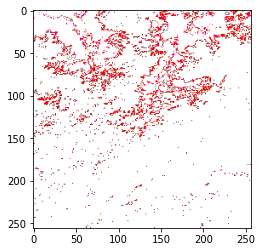

In [29]:
im = get_translate([10488383.273178745,3209132.19552484,10527519.031660756,3248267.954006849])
plt.imshow(im)

In [3]:
transformer = Transformer.from_crs("EPSG:32611", "EPSG:4326")
transformer.transform(320067,4156031)

(37.533720613610896, -119.0364743667522)

In [2]:
t = time.time()
fp = 'http://landsat-pds.s3.amazonaws.com/c1/L8/042/034/LC08_L1TP_042034_20170616_20170629_01_T1/LC08_L1TP_042034_20170616_20170629_01_T1_B4.TIF'

# See the profile
with rasterio.open(fp) as src:
    #print(src.profile)
#with rasterio.open(fp) as src:
    # List of overviews from biggest to smallest
    oviews = src.overviews(1)

    # Retrieve the smallest thumbnail
    oview = oviews[2]
    #print('Decimation factor= {}'.format(oview))
    # NOTE this is using a 'decimated read' (http://rasterio.readthedocs.io/en/latest/topics/resampling.html)
    thumbnail = src.read(1, out_shape=(1, int(src.height // oview), int(src.width // oview)))
print(time.time()-t)

19.589053630828857


array type:  <class 'numpy.ndarray'>
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


Text(0, 0.5, 'Row #')

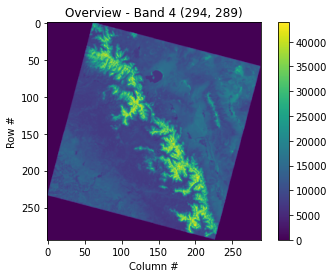

In [3]:
print('array type: ',type(thumbnail))
print(thumbnail)

plt.imshow(thumbnail)
plt.colorbar()
plt.title('Overview - Band 4 {}'.format(thumbnail.shape))
plt.xlabel('Column #')
plt.ylabel('Row #')

In [14]:
def get_translate():
    # dataset = gdal.Open('/vsicurl/http://landsat-pds.s3.amazonaws.com/c1/L8/042/034/LC08_L1TP_042034_20170616_20170629_01_T1/LC08_L1TP_042034_20170616_20170629_01_T1_B4.TIF')
    dataset = gdal.Open('example/LE70220491999322EDC01_stack.gtif', gdal.GA_ReadOnly)
    dataset = gdal.Warp('/vsimem/in_memory_output.tif', dataset, width=256, height=256, outputBounds=[462405.0, 1734315.0, 469905.0, 1741815.0])
    # dataset = gdal.Warp('/vsimem/in_memory_output.tif', dataset, width=256, height=256, outputBounds=[264285.0, 4629585.0, 388915.0, 3668115.0])
    return dataset.GetRasterBand(1).ReadAsArray()
get_translate()

array([[569, 526, 569, ..., 311, 289, 311],
       [568, 589, 568, ..., 267, 332, 332],
       [546, 525, 589, ..., 311, 311, 311],
       ...,
       [499, 543, 478, ..., 306, 349, 372],
       [520, 520, 543, ..., 328, 372, 393],
       [543, 564, 543, ..., 393, 414, 436]], dtype=int16)

In [12]:
dataset = gdal.Open('example/LE70220491999322EDC01_stack.gtif', gdal.GA_ReadOnly)
dataset = gdal.Warp('/vsimem/in_memory_output.tif', dataset, width=256, height=256, outputBounds=[462405.0, 1734315.0, 469905.0, 1741815.0])
dataset.GetRasterBand(1).ReadAsArray()    

array([[569, 526, 569, ..., 311, 289, 311],
       [568, 589, 568, ..., 267, 332, 332],
       [546, 525, 589, ..., 311, 311, 311],
       ...,
       [499, 543, 478, ..., 306, 349, 372],
       [520, 520, 543, ..., 328, 372, 393],
       [543, 564, 543, ..., 393, 414, 436]], dtype=int16)

In [6]:
# Open a GDAL dataset
dataset = gdal.Open('example/LE70220491999322EDC01_stack.gtif', gdal.GA_ReadOnly)
a = dataset.ReadAsArray()

print(dataset)

<osgeo.gdal.Dataset; proxy of <Swig Object of type 'GDALDatasetShadow *' at 0x7f295bfe9f60> >


https://trac.osgeo.org/gdal/wiki/CloudOptimizedGeoTIFF

Input format for GDAL translate:<br />
&nbsp;&nbsp;`/vsicurl/` -- http serving dataset<br />
&nbsp;&nbsp;`/vsis3/` -- AWS S3 serving dataset<br />
&nbsp;&nbsp;`/vsimem/` -- Reading dataset from RAM<br />
<br />
Output format -<br />
&nbsp;&nbsp;`format=MEM` returns output<br />
&nbsp;&nbsp;Else saves to location on disk

In [4]:
# Open a GDAL dataset
# for http -> /vsicurl/http://example.com/path/to/some.tif
# for AWS S3 private files -> /vsis3/
import time
t = time.time()
dataset = gdal.Open('/vsicurl/http://landsat-pds.s3.amazonaws.com/c1/L8/042/034/LC08_L1TP_042034_20170616_20170629_01_T1/LC08_L1TP_042034_20170616_20170629_01_T1_B4.TIF')
# dataset = gdal.Translate('/vsimem/in_memory_output.tif', dataset, width=256, height=256, projWin = [264285.0, 4629585.0, 388915.0, 3668115.0])
dataset = gdal.Warp('/vsimem/in_memory_output.tif', dataset, width=256, height=256, outputBounds=[204285, 4029585, 438915, 4268115])
print(time.time()-t)
print(dataset)

30.405049085617065
<osgeo.gdal.Dataset; proxy of <Swig Object of type 'GDALDatasetShadow *' at 0x7f182e031db0> >


In [16]:
# Open a GDAL dataset
# for http -> /vsicurl/http://example.com/path/to/some.tif
# for AWS S3 private files -> /vsis3/
import time
t = time.time()
dataset = gdal.Open('/vsicurl/http://landsat-pds.s3.amazonaws.com/c1/L8/042/034/LC08_L1TP_042034_20170616_20170629_01_T1/LC08_L1TP_042034_20170616_20170629_01_T1_B4.TIF')
# dataset = gdal.Translate('/vsimem/in_memory_output.tif', dataset, width=256, height=256, projWin = [264285.0, 4629585.0, 388915.0, 3668115.0])
dataset = gdal.Warp('', dataset, width=256, height=256, outputBounds=[258631,4196704,359770,4113954], format='MEM')
print(time.time()-t)
print(dataset)

3.2079601287841797
<osgeo.gdal.Dataset; proxy of <Swig Object of type 'GDALDatasetShadow *' at 0x7fc7e1d5a060> >


In [17]:
print(dataset.RasterXSize, dataset.RasterYSize, dataset.RasterCount)

256 256 1


In [3]:
dataset = gdal.Open('/vsicurl/http://landsat-pds.s3.amazonaws.com/c1/L8/042/034/LC08_L1TP_042034_20170616_20170629_01_T1/LC08_L1TP_042034_20170616_20170629_01_T1_B4.TIF')
dataset = gdal.Warp('/vsimem/in_memory_output.tif', dataset, width=256, height=256)

In [18]:
d = dataset.GetRasterBand(1).ReadAsArray()

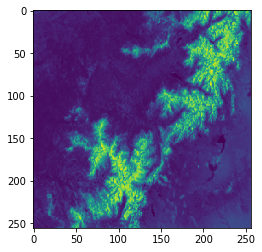

In [19]:
plt.imshow(d)

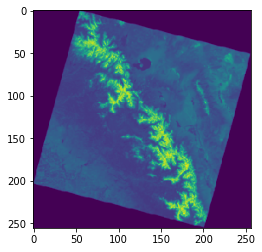

In [5]:
plt.imshow(d)

In [7]:
width = dataset.RasterXSize
height = dataset.RasterYSize
gt = dataset.GetGeoTransform()
minx = gt[0]
miny = gt[3] + width*gt[4] + height*gt[5] 
maxx = gt[0] + width*gt[1] + height*gt[2]
maxy = gt[3] 

In [8]:
gt

(204285.0, 916.5234375, 0.0, 4268115.0, 0.0, -931.7578125)

In [15]:
print(minx, miny, maxx, maxy)

204285.0 4029585.0 438915.0 4268115.0


In [9]:
print(minx, miny, maxx, maxy)

204285.0 4029585.0 438915.0 4268115.0


In [7]:
help(gdal.Translate)

Help on function Translate in module osgeo.gdal:

Translate(destName, srcDS, **kwargs)
    Convert a dataset.
    Arguments are :
      destName --- Output dataset name
      srcDS --- a Dataset object or a filename
    Keyword arguments are :
      options --- return of gdal.TranslateOptions(), string or array of strings
      other keywords arguments of gdal.TranslateOptions()
    If options is provided as a gdal.TranslateOptions() object, other keywords are ignored.



In [8]:
help(gdal.ReprojectImage)

Help on function ReprojectImage in module osgeo.gdal:

ReprojectImage(*args, **kwargs)
    ReprojectImage(Dataset src_ds, Dataset dst_ds, char const * src_wkt=None, char const * dst_wkt=None, GDALResampleAlg eResampleAlg, double WarpMemoryLimit=0.0, double maxerror=0.0, GDALProgressFunc callback=0, void * callback_data=None, char ** options=None) -> CPLErr



In [27]:
?gdal.TranslateOptions

In [3]:
?gdal.WarpOptions

In [4]:
type(dataset)

osgeo.gdal.Dataset

In [5]:
# ds = gdal.Warp('/vsimem/in_memory_output.tif', dataset)
ds = gdal.Translate('/vsimem/in_memory_output.tif', dataset, projWin = [462405.0, 1734315.0, 469905.0, 1741815.0])# lattitude

In [6]:
type(ds)

NoneType

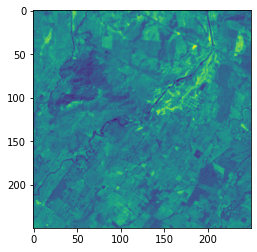

In [28]:
img = np.zeros((dataset.RasterYSize, dataset.RasterXSize, dataset.RasterCount),
               gdal_array.GDALTypeCodeToNumericTypeCode(dataset.GetRasterBand(1).DataType))
for b in range(img.shape[2]):
    img[:, :, b] = dataset.GetRasterBand(b + 1).ReadAsArray()
plt.imshow(img[:, :, 4])

In [27]:
ds = gdal.Warp('/vsimem/in_memory_output.tif', dataset,  outputBounds=[462405.0, 1734315.0, 469905.0, 1741815.0])
type(ds)

osgeo.gdal.Dataset

In [9]:
ds = gdal.Warp('/vsimem/in_memory_output.tif', dataset, width=256, height=256, outputBounds=[462405.0, 1734315.0, 469905.0, 1741815.0])
type(ds)

osgeo.gdal.Dataset

In [10]:
out_arr = ds.ReadAsArray()
out_arr.shape

(8, 256, 256)

In [30]:
out_arr = ds.ReadAsArray()
out_arr.shape

(8, 256, 256)

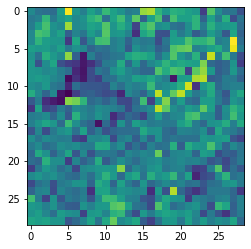

In [16]:
img = np.zeros((ds.RasterYSize, ds.RasterXSize, ds.RasterCount),
               gdal_array.GDALTypeCodeToNumericTypeCode(ds.GetRasterBand(1).DataType))
for b in range(img.shape[2]):
    img[:, :, b] = ds.GetRasterBand(b + 1).ReadAsArray()
plt.imshow(img[:, :, 4])

In [23]:
ds = gdal.Warp('/vsimem/in_memory_output.tif', dataset, outputBounds=[-75.3, 5.5, -73.5, 3.7])
out_arr = ds.ReadAsArray()
out_arr.shape

AttributeError: 'NoneType' object has no attribute 'ReadAsArray'